In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv
load_dotenv()  

True

In [2]:
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash")

In [3]:
class BlogState(TypedDict):

    title: str
    outline: str
    content: str

In [4]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = llm.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [5]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = llm.invoke(prompt).content

    state['content'] = content

    return state

In [6]:
graph = StateGraph(BlogState)

graph.add_node('create_outline',create_outline)
graph.add_node('create_blog',create_blog)

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()

In [7]:
initial_state = {'title': 'Rise of AI in India'}

final_state = workflow.invoke(initial_state)

print(final_state)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


{'title': 'Rise of AI in India', 'outline': [{'type': 'text', 'text': 'Here is a detailed, SEO-friendly blog outline on the topic **"Rise of AI in India."** \n\nThis outline is structured to guide a writer through creating a comprehensive, engaging, and highly readable blog post of approximately 1,500 to 2,500 words.\n\n---\n\n# Blog Outline: The Rise of AI in India: From IT Hub to Global AI Powerhouse\n\n## **Catchy Title Options**\n*   **Option 1:** The Indian AI Renaissance: How India is Redefining the Global Tech Landscape\n*   **Option 2:** From IT Outsourcing to AI Innovation: The Rise of Artificial Intelligence in India\n*   **Option 3:** Silicon Valley of the East? Inside India’s Massive AI Revolution\n*   **Option 4:** AI for 1.4 Billion: How India is Democratizing Artificial Intelligence\n\n---\n\n## **1. Introduction**\n*   **Hook:** Start with a compelling contrast—how India, once known as the world’s "back-office" for IT outsourcing, is now pioneering cutting-edge AI solut

In [11]:
print(final_state)

{'title': 'Rise of AI in India', 'outline': [{'type': 'text', 'text': 'Here is a detailed, SEO-friendly blog outline on the topic **"Rise of AI in India."** \n\nThis outline is structured to guide a writer through creating a comprehensive, engaging, and highly readable blog post of approximately 1,500 to 2,500 words.\n\n---\n\n# Blog Outline: The Rise of AI in India: From IT Hub to Global AI Powerhouse\n\n## **Catchy Title Options**\n*   **Option 1:** The Indian AI Renaissance: How India is Redefining the Global Tech Landscape\n*   **Option 2:** From IT Outsourcing to AI Innovation: The Rise of Artificial Intelligence in India\n*   **Option 3:** Silicon Valley of the East? Inside India’s Massive AI Revolution\n*   **Option 4:** AI for 1.4 Billion: How India is Democratizing Artificial Intelligence\n\n---\n\n## **1. Introduction**\n*   **Hook:** Start with a compelling contrast—how India, once known as the world’s "back-office" for IT outsourcing, is now pioneering cutting-edge AI solut

In [10]:
print(final_state["content"])

[{'type': 'text', 'text': '# From IT Outsourcing to AI Innovation: Inside the Rise of AI in India\n\nIn the late 1990s and early 2000s, India cemented its reputation on the global stage as the world’s Premier IT back-office. During the Y2K crisis, thousands of Indian software engineers worked tirelessly behind the scenes, debugging legacy code and keeping the global financial system afloat. For the next two decades, "outsourcing to India" became the default strategy for Fortune 500 companies looking to streamline software maintenance, database management, and customer support. \n\nFast forward to today. In the bustling tech hubs of Bengaluru, Hyderabad, and Noida, the narrative has fundamentally changed. Indian engineers are no longer just maintaining legacy systems; they are building foundational Large Language Models (LLMs), deploying computer vision technologies to remote villages, and training next-generation neural networks. \n\nAs generative AI and advanced machine learning redra

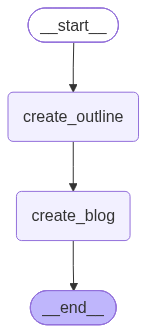

In [8]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())